In [21]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Download latest version
path = kagglehub.dataset_download("die9origephit/fifa-world-cup-2022-complete-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fifa-world-cup-2022-complete-dataset' dataset.
Path to dataset files: /kaggle/input/fifa-world-cup-2022-complete-dataset


In [22]:
import os

# List all files in the downloaded dataset directory
files = os.listdir(path)
print("Files in dataset:", files)

# Find CSV files and load the main one (or the first one found)
csv_files = [f for f in files if f.endswith('.csv')]
if csv_files:
    # We'll display the files and read the first CSV file as a start
    main_file_path = os.path.join(path, csv_files[0])
    print(f"\nLoading: {csv_files[0]}")
    df = pd.read_csv(main_file_path)
    display(df.head())
else:
    print("No CSV files found in the dataset directory.")

Files in dataset: ['Fifa_world_cup_matches.csv']

Loading: Fifa_world_cup_matches.csv


,team1,team2,possession team1,possession team2,possession in contest,number of goals team1,number of goals team2,date,hour,category,...,penalties scored team1,penalties scored team2,goal preventions team1,goal preventions team2,own goals team1,own goals team2,forced turnovers team1,forced turnovers team2,defensive pressures applied team1,defensive pressures applied team2
0,QATAR,ECUADOR,42%,50%,8%,0,2,20 NOV 2022,17 : 00,Group A,...,0,1,6,5,0,0,52,72,256,279
1,ENGLAND,IRAN,72%,19%,9%,6,2,21 NOV 2022,14 : 00,Group B,...,0,1,8,13,0,0,63,72,139,416
2,SENEGAL,NETHERLANDS,44%,45%,11%,0,2,21 NOV 2022,17 : 00,Group A,...,0,0,9,15,0,0,63,73,263,251
3,UNITED STATES,WALES,51%,39%,10%,1,1,21 NOV 2022,20 : 00,Group B,...,0,1,7,7,0,0,81,72,242,292
4,ARGENTINA,SAUDI ARABIA,64%,24%,12%,1,2,22 NOV 2022,11 : 00,Group C,...,1,0,4,14,0,0,65,80,163,361


In [23]:
# 1. Cek Duplikat
initial_rows = df.shape[0]
df = df.drop_duplicates()
print(f"Jumlah baris duplikat yang dihapus: {initial_rows - df.shape[0]}")

# 2. Cek Missing Values
missing_values = df.isnull().sum()
columns_with_missing = missing_values[missing_values > 0]
if len(columns_with_missing) > 0:
    print("\nKolom dengan nilai kosong dan jumlahnya:")
    print(columns_with_missing)
else:
    print("\nTidak ada missing values dalam dataset.")

# Reload df first to recover original 'date' before previous failed conversion
df = pd.read_csv(main_file_path)

# 3. Memperbaiki Tipe Data (Persentase dan Tanggal)
# Mengonversi kolom kepemilikan bola (possession) dari string % ke numerik float
for col in ['possession team1', 'possession team2', 'possession in contest']:
    if col in df.columns and df[col].dtype == 'object':
        df[col] = df[col].astype(str).str.rstrip('%').astype('float') / 100.0

# Mengonversi format tanggal menjadi datetime (menggunakan case-insensitive parsing / uppercase manual)
if 'date' in df.columns:
    # Ubah format tanggal (contoh: '20 NOV 2022' -> diubah ke title case agar format %b bekerja)
    date_cleaned = df['date'].astype(str).str.strip().str.title()
    df['date'] = pd.to_datetime(date_cleaned, format='%d %b %Y', errors='coerce')

# 4. Standardisasi Kategori (Nama Tim menjadi Title Case)
if 'team1' in df.columns and 'team2' in df.columns:
    df['team1'] = df['team1'].astype(str).str.strip().str.title()
    df['team2'] = df['team2'].astype(str).str.strip().str.title()

# 5. Deteksi Outliers awal pada variabel numerik kunci (misalnya total gol)
if 'number of goals team1' in df.columns and 'number of goals team2' in df.columns:
    df['total_goals'] = df['number of goals team1'] + df['number of goals team2']

    # Deteksi IQR untuk total_goals
    Q1 = df['total_goals'].quantile(0.25)
    Q3 = df['total_goals'].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df['total_goals'] < lower_bound) | (df['total_goals'] > upper_bound)]
    print(f"\nDeteksi Pencilan (Outliers) berdasarkan total gol (Batas: {lower_bound} - {upper_bound}):")
    print(f"Jumlah pertandingan outlier: {len(outliers)}")
    if len(outliers) > 0:
        display(outliers[['team1', 'team2', 'number of goals team1', 'number of goals team2', 'total_goals']])

print("\nHasil akhir informasi dataset setelah dibersihkan:")
print(df.info())

Jumlah baris duplikat yang dihapus: 0

Tidak ada missing values dalam dataset.

Deteksi Pencilan (Outliers) berdasarkan total gol (Batas: -2.375 - 6.625):
Jumlah pertandingan outlier: 3


,team1,team2,number of goals team1,number of goals team2,total_goals
1,England,Iran,6,2,8
10,Spain,Costa Rica,7,0,7
55,Portugal,Switzerland,6,1,7



Hasil akhir informasi dataset setelah dibersihkan:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 89 columns):
 #   Column                                                 Non-Null Count  Dtype         
---  ------                                                 --------------  -----         
 0   team1                                                  64 non-null     object        
 1   team2                                                  64 non-null     object        
 2   possession team1                                       64 non-null     float64       
 3   possession team2                                       64 non-null     float64       
 4   possession in contest                                  64 non-null     float64       
 5   number of goals team1                                  64 non-null     int64         
 6   number of goals team2                                  64 non-null     int64         
 7   date                 

=== STATISTIK DESKRIPTIF KUNCI ===


,total_goals,possession team1,possession team2,total attempts team1,total attempts team2,corners team1,corners team2
mean,2.687500,0.44625,0.435312,11.140625,11.281250,4.484375,4.453125
median,2.000000,0.46000,0.425000,10.000000,10.000000,4.500000,4.000000
std,1.892969,0.11917,0.119854,4.972519,5.807682,2.777416,2.794153


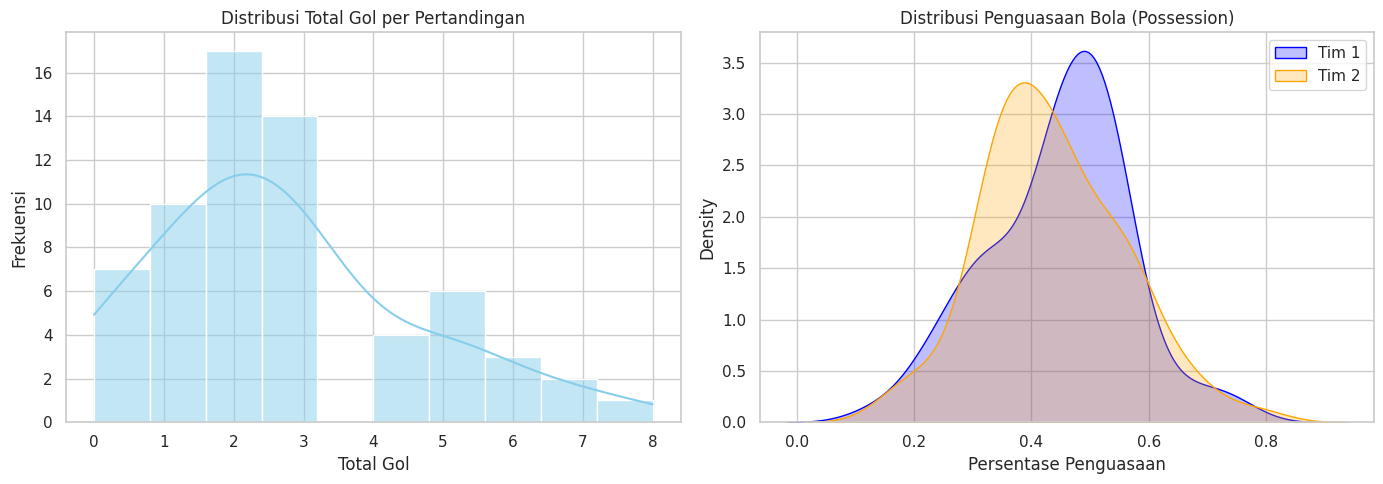

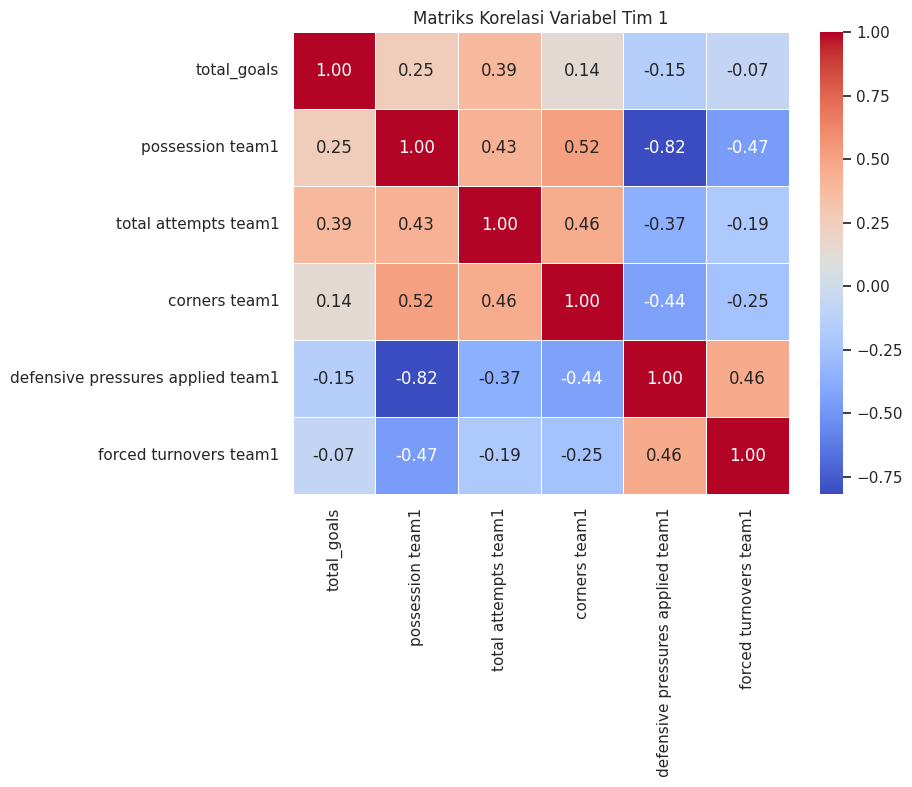

=== ANALISIS POLA AWAL & HIPOTESIS ===
1. Apakah penguasaan bola berkorelasi kuat dengan jumlah tembakan (total attempts)?
   Korelasi: 0.43
2. Apakah total attempts berkorelasi dengan total gol yang tercipta?
   Korelasi: 0.39


In [24]:
# 1. Statistik Deskriptif Dasar
key_metrics = ['total_goals', 'possession team1', 'possession team2',
               'total attempts team1', 'total attempts team2',
               'corners team1', 'corners team2']

print("=== STATISTIK DESKRIPTIF KUNCI ===")
stats_df = df[key_metrics].describe().loc[['mean', '50%', 'std']]
stats_df.rename(index={'50%': 'median'}, inplace=True)
display(stats_df)

# 2. Distribusi Data (Total Gol & Penguasaan Bola)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['total_goals'], kde=True, bins=10, color='skyblue')
plt.title('Distribusi Total Gol per Pertandingan')
plt.xlabel('Total Gol')
plt.ylabel('Frekuensi')

plt.subplot(1, 2, 2)
sns.kdeplot(df['possession team1'], fill=True, label='Tim 1', color='blue')
sns.kdeplot(df['possession team2'], fill=True, label='Tim 2', color='orange')
plt.title('Distribusi Penguasaan Bola (Possession)')
plt.xlabel('Persentase Penguasaan')
plt.legend()

plt.tight_layout()
plt.show()

# 3. Analisis Korelasi Antar Variabel Kunci
correlation_metrics = [
    'total_goals', 'possession team1', 'total attempts team1',
    'corners team1', 'defensive pressures applied team1', 'forced turnovers team1'
]

plt.figure(figsize=(8, 6))
corr_matrix = df[correlation_metrics].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriks Korelasi Variabel Tim 1')
plt.show()

# Menampilkan temuan awal / pola berdasarkan korelasi
print("=== ANALISIS POLA AWAL & HIPOTESIS ===")
print("1. Apakah penguasaan bola berkorelasi kuat dengan jumlah tembakan (total attempts)?")
print(f"   Korelasi: {corr_matrix.loc['possession team1', 'total attempts team1']:.2f}")
print("2. Apakah total attempts berkorelasi dengan total gol yang tercipta?")
print(f"   Korelasi: {corr_matrix.loc['total_goals', 'total attempts team1']:.2f}")

=== ANALISIS DESKRIPTIF HIPOTESIS 1 ===
Rata-rata Konversi Gol (Possession > 60%): 0.1420 (n = 8)
Rata-rata Konversi Gol (Possession <= 60%): 0.1284 (n = 120)

=== HASIL UJI SIGNIFIKANSI (T-TEST) ===
T-Statistic: 0.2058
P-Value: 0.8424

Kesimpulan: Gagal menolak H0. Tidak ada bukti statistik yang cukup untuk menyatakan bahwa tim dengan possession tinggi memiliki konversi gol yang lebih baik.


/tmp/ipykernel_2751/4110573079.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=teams_perf['possession'] > 0.60, y=teams_perf['conversion_rate'], palette='Set2')


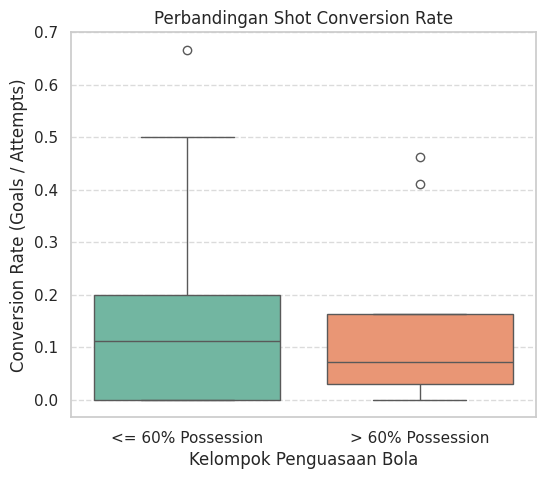

In [25]:
from scipy import stats

# 1. Ekstrak data performa per tim dari setiap pertandingan
# Kita akan membuat dataset terpisah di mana setiap baris mewakili statistik satu tim dalam satu pertandingan
team1_df = df[['team1', 'possession team1', 'number of goals team1', 'total attempts team1']].copy()
team1_df.columns = ['team', 'possession', 'goals', 'attempts']

team2_df = df[['team2', 'possession team2', 'number of goals team2', 'total attempts team2']].copy()
team2_df.columns = ['team', 'possession', 'goals', 'attempts']

# Gabungkan data kedua tim
teams_perf = pd.concat([team1_df, team2_df], ignore_index=True)

# 2. Hitung Shot Conversion Rate (Gol per Tembakan)
# Hindari pembagian dengan nol jika ada tim yang tidak melakukan tembakan
teams_perf['conversion_rate'] = np.where(teams_perf['attempts'] > 0, teams_perf['goals'] / teams_perf['attempts'], 0)

# 3. Bagi menjadi kelompok Possession > 60% dan <= 60%
high_possession = teams_perf[teams_perf['possession'] > 0.60]['conversion_rate']
low_possession = teams_perf[teams_perf['possession'] <= 0.60]['conversion_rate']

print("=== ANALISIS DESKRIPTIF HIPOTESIS 1 ===")
print(f"Rata-rata Konversi Gol (Possession > 60%): {high_possession.mean():.4f} (n = {len(high_possession)})")
print(f"Rata-rata Konversi Gol (Possession <= 60%): {low_possession.mean():.4f} (n = {len(low_possession)})")

# 4. Uji Hipotesis menggunakan T-Test Independen
t_stat, p_val = stats.ttest_ind(high_possession, low_possession, equal_var=False)

print("\n=== HASIL UJI SIGNIFIKANSI (T-TEST) ===")
print(f"T-Statistic: {t_stat:.4f}")
print(f"P-Value: {p_val:.4f}")

# Kesimpulan
alpha = 0.05
if p_val < alpha:
    print("\nKesimpulan: Tolak H0. Ada perbedaan signifikan secara statistik pada tingkat konversi gol antara tim dengan possession tinggi dan rendah.")
else:
    print("\nKesimpulan: Gagal menolak H0. Tidak ada bukti statistik yang cukup untuk menyatakan bahwa tim dengan possession tinggi memiliki konversi gol yang lebih baik.")

# Visualisasi perbandingan
plt.figure(figsize=(6, 5))
sns.boxplot(x=teams_perf['possession'] > 0.60, y=teams_perf['conversion_rate'], palette='Set2')
plt.xticks([0, 1], ['<= 60% Possession', '> 60% Possession'])
plt.title('Perbandingan Shot Conversion Rate')
plt.ylabel('Conversion Rate (Goals / Attempts)')
plt.xlabel('Kelompok Penguasaan Bola')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

=== ANALISIS KORELASI HIPOTESIS 2 ===
Korelasi Pearson: 0.8411 (p-value: 1.9520e-35)
Korelasi Spearman: 0.8371 (p-value: 8.4274e-35)

Kesimpulan: Terdapat hubungan yang signifikan secara statistik (kuat positif) 
antara defensive pressure yang diterapkan dengan penguasaan bola lawan.


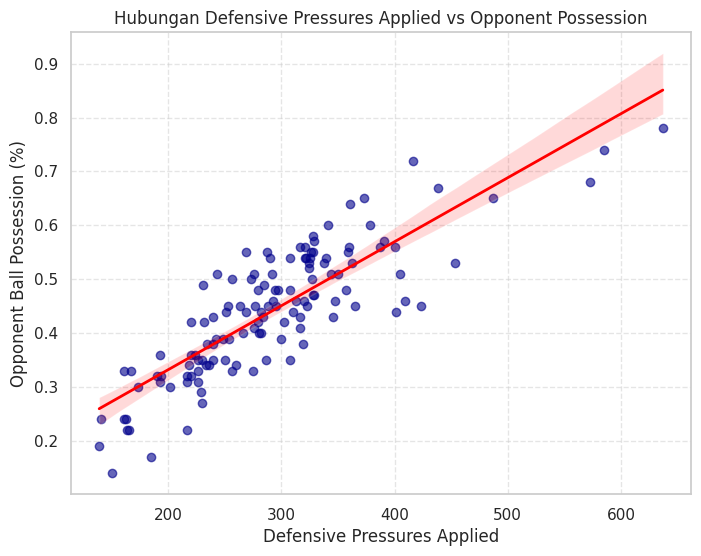

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Pasangkan data defensive pressures sebuah tim dengan possession tim lawan
# Kita ambil defensive pressures Team 1 vs possession Team 2
matchup1 = pd.DataFrame({
    'defensive_pressures': df['defensive pressures applied team1'],
    'opponent_possession': df['possession team2']
})

# Kita ambil defensive pressures Team 2 vs possession Team 1
matchup2 = pd.DataFrame({
    'defensive_pressures': df['defensive pressures applied team2'],
    'opponent_possession': df['possession team1']
})

# Gabungkan kedua dataset
defense_vs_possession = pd.concat([matchup1, matchup2], ignore_index=True)

# 2. Hitung korelasi Pearson dan Spearman
pearson_corr, p_val_pearson = stats.pearsonr(defense_vs_possession['defensive_pressures'], defense_vs_possession['opponent_possession'])
spearman_corr, p_val_spearman = stats.spearmanr(defense_vs_possession['defensive_pressures'], defense_vs_possession['opponent_possession'])

print("=== ANALISIS KORELASI HIPOTESIS 2 ===")
print(f"Korelasi Pearson: {pearson_corr:.4f} (p-value: {p_val_pearson:.4e})")
print(f"Korelasi Spearman: {spearman_corr:.4f} (p-value: {p_val_spearman:.4e})")

# Kesimpulan analisis
if p_val_pearson < 0.05:
    direction = "negatif" if pearson_corr < 0 else "positif"
    strength = "kuat" if abs(pearson_corr) > 0.5 else "sedang" if abs(pearson_corr) > 0.3 else "lemah"
    print(f"\nKesimpulan: Terdapat hubungan yang signifikan secara statistik ({strength} {direction}) ")
    print("antara defensive pressure yang diterapkan dengan penguasaan bola lawan.")
else:
    print("\nKesimpulan: Tidak ada hubungan yang signifikan secara statistik antara defensive pressure dengan penguasaan bola lawan.")

# 3. Visualisasi Scatter Plot dengan Regression Line
plt.figure(figsize=(8, 6))
sns.regplot(data=defense_vs_possession, x='defensive_pressures', y='opponent_possession',
            scatter_kws={'alpha':0.6, 'color':'darkblue'}, line_kws={'color':'red', 'linewidth':2})
plt.title('Hubungan Defensive Pressures Applied vs Opponent Possession')
plt.xlabel('Defensive Pressures Applied')
plt.ylabel('Opponent Ball Possession (%)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

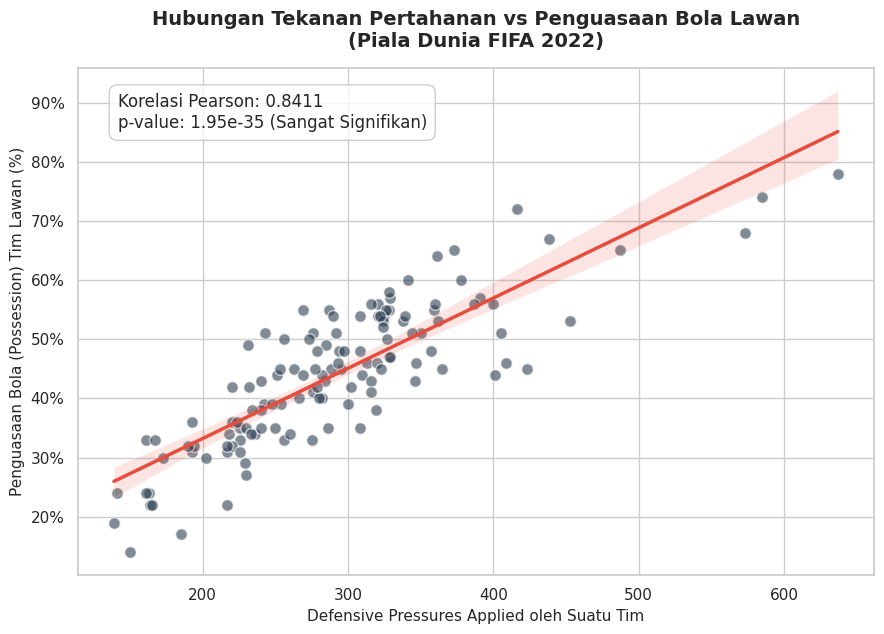

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur gaya visualisasi
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 6.5))

# Membuat scatter plot dengan garis regresi
sns.regplot(
    data=defense_vs_possession,
    x='defensive_pressures',
    y='opponent_possession',
    scatter_kws={'alpha': 0.6, 'color': '#2c3e50', 'edgecolor': 'w', 's': 70},
    line_kws={'color': '#e74c3c', 'linewidth': 2.5, 'label': 'Garis Tren (Regresi)'}
)

# Menambahkan anotasi statistik korelasi di dalam plot
text_stats = f"Korelasi Pearson: {pearson_corr:.4f}\np-value: {p_val_pearson:.2e} (Sangat Signifikan)"
plt.text(
    0.05, 0.95, text_stats,
    transform=plt.gca().transAxes,
    verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='#bdc3c7')
)

# Mengatur judul dan label
plt.title('Hubungan Tekanan Pertahanan vs Penguasaan Bola Lawan\n(Piala Dunia FIFA 2022)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Defensive Pressures Applied oleh Suatu Tim', fontsize=11)
plt.ylabel('Penguasaan Bola (Possession) Tim Lawan (%)', fontsize=11)

# Memformat sumbu Y ke format persentase jika diperlukan (karena datanya berupa proporsi 0.0 - 1.0)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))

plt.tight_layout()
plt.show()

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Menggabungkan data taktis per tim dari setiap pertandingan
tactical1 = df[[
    'team1', 'crosses team1', 'crosses completed team1',
    'forced turnovers team1', 'defensive pressures applied team1',
    'possession team1', 'number of goals team1', 'total attempts team1'
]].copy()
tactical1.columns = ['team', 'crosses', 'crosses_completed', 'forced_turnovers', 'defensive_pressures', 'possession', 'goals', 'attempts']

tactical2 = df[[
    'team2', 'crosses team2', 'crosses completed team2',
    'forced turnovers team2', 'defensive pressures applied team2',
    	'possession team2', 'number of goals team2', 'total attempts team2'
]].copy()
tactical2.columns = ['team', 'crosses', 'crosses_completed', 'forced_turnovers', 'defensive_pressures', 'possession', 'goals', 'attempts']

# Gabungkan data performa taktis
tactical_df = pd.concat([tactical1, tactical2], ignore_index=True)

# Hitung metrik baru
# Rasio akurasi umpan silang (Crosses Accuracy)
tactical_df['crosses_accuracy'] = np.where(tactical_df['crosses'] > 0, tactical_df['crosses_completed'] / tactical_df['crosses'], 0)

print("=== ANALISIS DESKRIPTIF FITUR TAKTIS ===")
print(f"Rata-rata Umpan Silang (Crosses) per Tim per Laga : {tactical_df['crosses'].mean():.2f}")
print(f"Rata-rata Umpan Silang Sukses (Completed)         : {tactical_df['crosses_completed'].mean():.2f}")
print(f"Rata-rata Akurasi Umpan Silang                   : {tactical_df['crosses_accuracy'].mean():.2%}")
print(f"Rata-rata Forced Turnovers per Tim per Laga       : {tactical_df['forced_turnovers'].mean():.2f}")

# 2. Korelasi antar metrik taktis baru
corr_tactical = tactical_df[[
    'crosses', 'crosses_completed', 'crosses_accuracy',
    'forced_turnovers', 'defensive_pressures', 'possession', 'goals', 'attempts'
]].corr()

print("\n=== MATRIKS KORELASI FITUR TAKTIS ===")
display(corr_tactical[['goals', 'attempts', 'possession', 'forced_turnovers']])

=== ANALISIS DESKRIPTIF FITUR TAKTIS ===
Rata-rata Umpan Silang (Crosses) per Tim per Laga : 18.31
Rata-rata Umpan Silang Sukses (Completed)         : 4.34
Rata-rata Akurasi Umpan Silang                   : 23.78%
Rata-rata Forced Turnovers per Tim per Laga       : 71.05

=== MATRIKS KORELASI FITUR TAKTIS ===


,goals,attempts,possession,forced_turnovers
crosses,0.046608,0.562528,0.552643,-0.082181
crosses_completed,0.159931,0.495080,0.353392,-0.118235
crosses_accuracy,0.146022,0.121955,-0.074988,-0.044739
forced_turnovers,0.116481,-0.140836,-0.432096,1.000000
defensive_pressures,-0.059978,-0.401558,-0.799998,0.469775
possession,0.129725,0.477508,1.000000,-0.432096
goals,1.000000,0.347128,0.129725,0.116481
attempts,0.347128,1.000000,0.477508,-0.140836


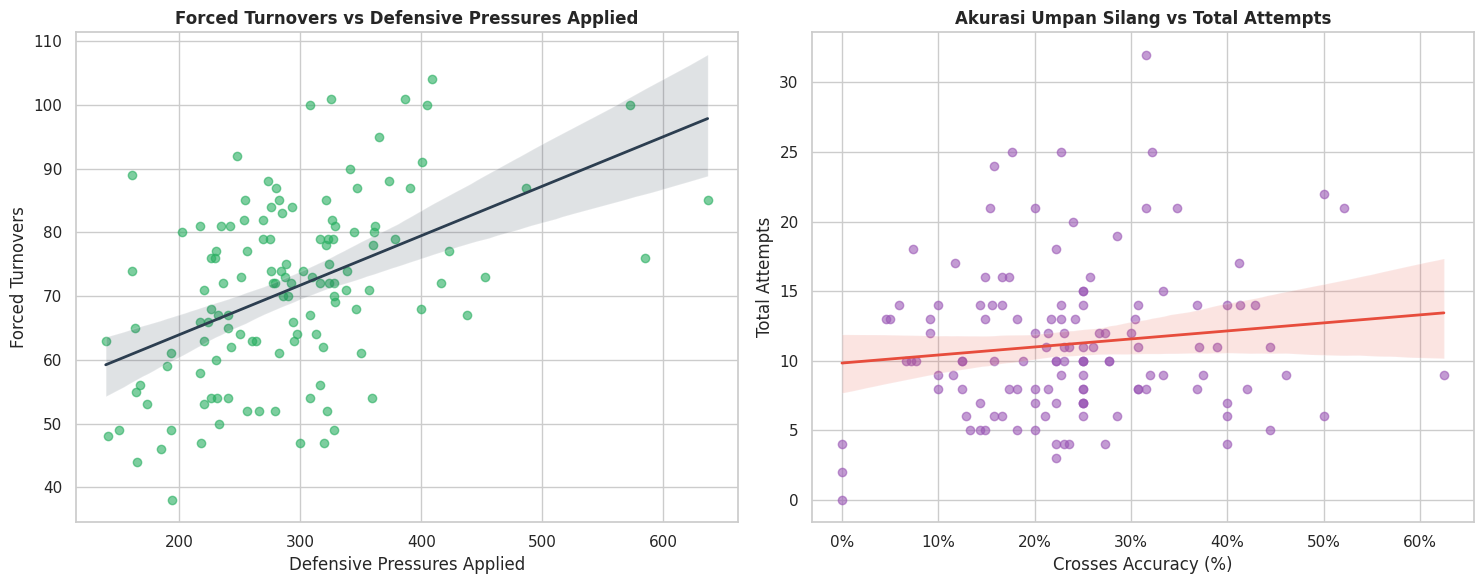

In [29]:
# 3. Visualisasi Fitur Taktis
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot A: Hubungan antara Forced Turnovers dan Defensive Pressures
sns.regplot(
    ax=axes[0],
    data=tactical_df,
    x='defensive_pressures',
    y='forced_turnovers',
    scatter_kws={'alpha': 0.6, 'color': '#27ae60'},
    line_kws={'color': '#2c3e50', 'linewidth': 2}
)
axes[0].set_title('Forced Turnovers vs Defensive Pressures Applied', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Defensive Pressures Applied')
axes[0].set_ylabel('Forced Turnovers')

# Plot B: Akurasi Umpan Silang vs Total Tembakan
sns.regplot(
    ax=axes[1],
    data=tactical_df,
    x='crosses_accuracy',
    y='attempts',
    scatter_kws={'alpha': 0.6, 'color': '#9b59b6'},
    line_kws={'color': '#e74c3c', 'linewidth': 2}
)
axes[1].set_title('Akurasi Umpan Silang vs Total Attempts', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Crosses Accuracy (%)')
axes[1].set_ylabel('Total Attempts')
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: '{:.0%}'.format(x)))

plt.tight_layout()
plt.show()

=== TIM DENGAN RATA-RATA GOL TERTINGGI (MINIMAL 4 PERTANDINGAN) ===


,team,matches_played,avg_goals,avg_possession,avg_attempts,avg_crosses_accuracy,avg_forced_turnovers,avg_defensive_pressures
10,England,5,2.600000,0.578000,12.000000,0.323900,56.000000,199.000000
21,Portugal,5,2.400000,0.542000,12.400000,0.279743,60.600000,253.400000
11,France,7,2.285714,0.448571,14.428571,0.343775,74.857143,283.714286
26,Spain,4,2.250000,0.690000,12.750000,0.147004,60.000000,206.750000
0,Argentina,7,2.142857,0.511429,14.857143,0.235799,70.571429,241.142857
19,Netherlands,5,2.000000,0.450000,8.000000,0.180084,82.400000,310.000000
3,Brazil,5,1.600000,0.504000,18.000000,0.204243,72.200000,295.400000
15,Japan,4,1.250000,0.297500,10.500000,0.240152,79.750000,457.250000
27,Switzerland,4,1.250000,0.430000,9.000000,0.215343,70.000000,287.500000
24,Senegal,4,1.250000,0.397500,12.750000,0.287298,66.500000,269.250000


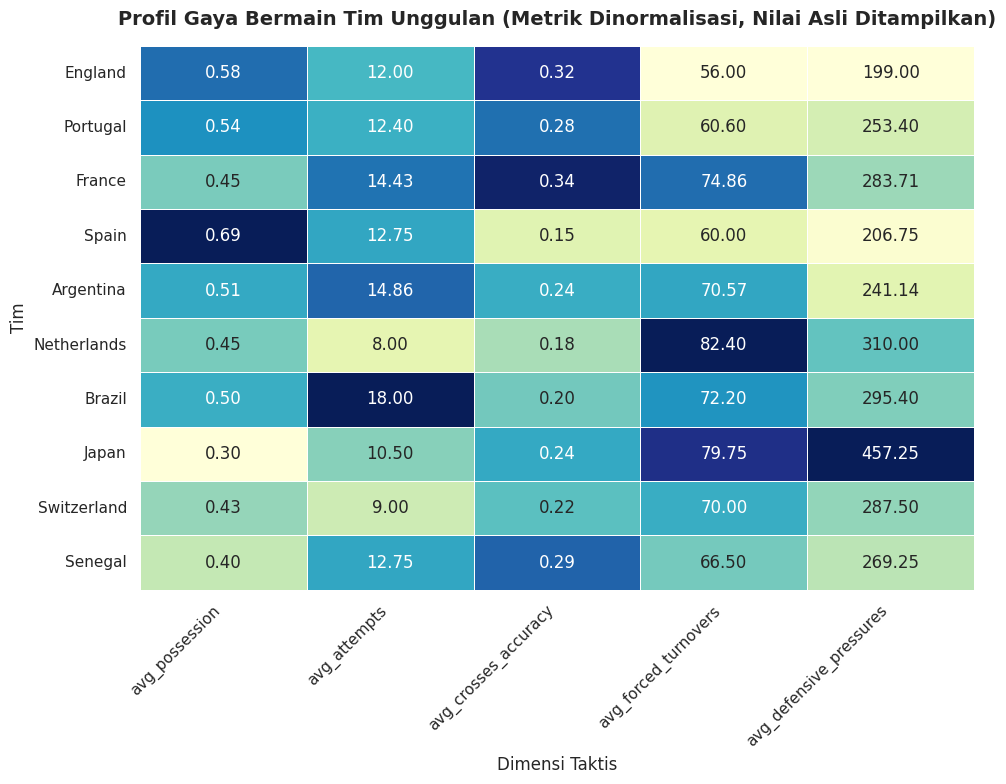

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Agregasikan data rata-rata taktis per tim
team_summary = tactical_df.groupby('team').agg(
    matches_played=('goals', 'count'),
    avg_goals=('goals', 'mean'),
    avg_possession=('possession', 'mean'),
    avg_attempts=('attempts', 'mean'),
    avg_crosses_accuracy=('crosses_accuracy', 'mean'),
    avg_forced_turnovers=('forced_turnovers', 'mean'),
    avg_defensive_pressures=('defensive_pressures', 'mean')
).reset_index()

# Saring tim papan atas yang memainkan minimal 4 pertandingan (mencapai babak gugur utama)
top_teams = team_summary[team_summary['matches_played'] >= 4].sort_values(by='avg_goals', ascending=False)

print("=== TIM DENGAN RATA-RATA GOL TERTINGGI (MINIMAL 4 PERTANDINGAN) ===")
display(top_teams.head(10))

# Standardisasi metrik untuk perbandingan gaya bermain (Heatmap)
top_10_teams = top_teams.head(10).copy()
metrics_to_plot = ['avg_possession', 'avg_attempts', 'avg_crosses_accuracy', 'avg_forced_turnovers', 'avg_defensive_pressures']

# Normalisasi sederhana (Min-Max) agar skala semua metrik setara untuk perbandingan visual di heatmap
normalized_top = top_10_teams[['team']].copy()
for col in metrics_to_plot:
    min_val = top_teams[col].min()
    max_val = top_teams[col].max()
    normalized_top[col] = (top_10_teams[col] - min_val) / (max_val - min_val)

normalized_top.set_index('team', inplace=True)

plt.figure(figsize=(10, 8))
sns.heatmap(normalized_top, annot=top_10_teams.set_index('team')[metrics_to_plot], fmt=".2f", cmap="YlGnBu", cbar=False, linewidths=.5)
plt.title('Profil Gaya Bermain Tim Unggulan (Metrik Dinormalisasi, Nilai Asli Ditampilkan)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Dimensi Taktis', fontsize=12)
plt.ylabel('Tim', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ekstrak data pertahanan per tim dari setiap pertandingan
defense1 = df[[
    'team1', 'goal preventions team1', 'conceded team1',
    'defensive pressures applied team1', 'forced turnovers team1'
]].copy()
defense1.columns = ['team', 'goal_preventions', 'conceded', 'defensive_pressures', 'forced_turnovers']

defense2 = df[[
    'team2', 'goal preventions team2', 'conceded team2',
    'defensive pressures applied team2', 'forced turnovers team2'
]].copy()
defense2.columns = ['team', 'goal_preventions', 'conceded', 'defensive_pressures', 'forced_turnovers']

# Gabungkan data performa pertahanan
defense_df = pd.concat([defense1, defense2], ignore_index=True)

# 2. Agregasikan rata-rata pertahanan per tim (minimal 4 pertandingan)
defense_summary = defense_df.groupby('team').agg(
    matches_played=('conceded', 'count'),
    avg_goal_preventions=('goal_preventions', 'mean'),
    avg_conceded=('conceded', 'mean'),
    avg_defensive_pressures=('defensive_pressures', 'mean'),
    avg_forced_turnovers=('forced_turnovers', 'mean')
).reset_index()

top_defensive_teams = defense_summary[defense_summary['matches_played'] >= 4].sort_values(by='avg_goal_preventions', ascending=False)

print("=== TIM DENGAN RATA-RATA GOAL PREVENTIONS TERTINGGI (MINIMAL 4 PERTANDINGAN) ===")
display(top_defensive_teams.head(10))

# 3. Hitung korelasi antara Goal Preventions dengan Kebobolan (Conceded)
corr_val = defense_df['goal_preventions'].corr(defense_df['conceded'])
print(f"\nKorelasi antara Goal Preventions dan Jumlah Kebobolan (Conceded): {corr_val:.4f}")

=== TIM DENGAN RATA-RATA GOAL PREVENTIONS TERTINGGI (MINIMAL 4 PERTANDINGAN) ===


,team,matches_played,avg_goal_preventions,avg_conceded,avg_defensive_pressures,avg_forced_turnovers
20,Poland,4,18.000000,1.250000,338.500000,67.500000
1,Australia,4,15.750000,1.500000,345.750000,76.750000
15,Japan,4,15.500000,1.000000,457.250000,79.750000
19,Netherlands,5,13.400000,0.800000,310.000000,82.400000
16,Korea Republic,4,12.500000,2.000000,284.750000,60.500000
7,Croatia,7,11.714286,1.000000,301.857143,78.285714
11,France,7,11.428571,1.142857,283.714286,74.857143
18,Morocco,7,11.000000,0.714286,359.428571,77.714286
27,Switzerland,4,10.250000,2.250000,287.500000,70.000000
21,Portugal,5,10.200000,1.200000,253.400000,60.600000



Korelasi antara Goal Preventions dan Jumlah Kebobolan (Conceded): 0.3380


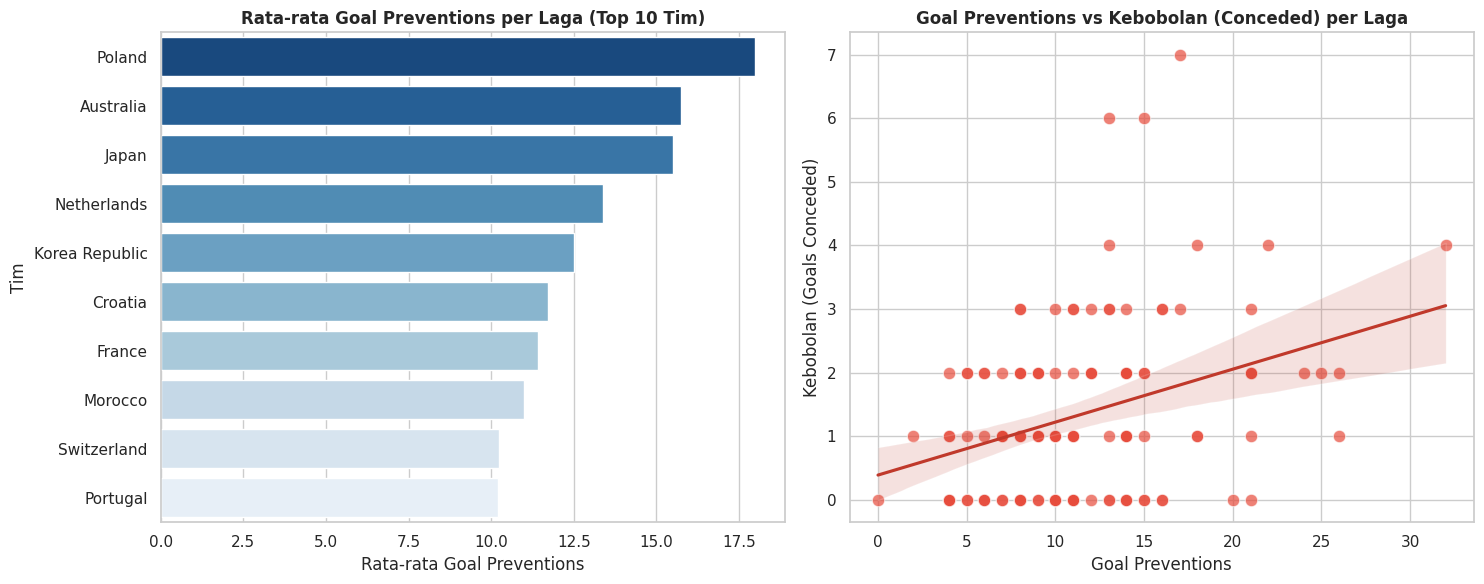

In [32]:
# 4. Visualisasi Kinerja Pertahanan
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot A: Tim dengan Goal Preventions Terbanyak
sns.barplot(
    ax=axes[0],
    data=top_defensive_teams.head(10),
    x='avg_goal_preventions',
    y='team',
    palette='Blues_r',
    hue='team',
    legend=False
)
axes[0].set_title('Rata-rata Goal Preventions per Laga (Top 10 Tim)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Rata-rata Goal Preventions')
axes[0].set_ylabel('Tim')

# Plot B: Korelasi Goal Preventions vs Kebobolan
sns.scatterplot(
    ax=axes[1],
    data=defense_df,
    x='goal_preventions',
    y='conceded',
    alpha=0.7,
    color='#e74c3c',
    s=80
)
sns.regplot(
    ax=axes[1],
    data=defense_df,
    x='goal_preventions',
    y='conceded',
    scatter=False,
    color='#c0392b'
)
axes[1].set_title('Goal Preventions vs Kebobolan (Conceded) per Laga', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Goal Preventions')
axes[1].set_ylabel('Kebobolan (Goals Conceded)')

plt.tight_layout()
plt.show()

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ekstrak kolom pelanggaran dan kartu dari dataset utama
# Kita cari nama kolom yang relevan menggunakan list comprehension untuk memastikan kecocokan nama
foul_cols = [col for col in df.columns if 'fouls' in col.lower() or 'card' in col.lower()]
print("Kolom yang berkaitan dengan pelanggaran/kartu:", foul_cols)

Kolom yang berkaitan dengan pelanggaran/kartu: ['yellow cards team1', 'yellow cards team2', 'red cards team1', 'red cards team2', 'fouls against team1', 'fouls against team2']


In [34]:
# 2. Menggabungkan data pelanggaran, kartu, dan performa defensif per tim dari setiap pertandingan
# Berdasarkan nama kolom yang umum ada di dataset FIFA:
# 'fouls against team1' (pelanggaran yang dilakukan oleh team1), 'yellow cards team1', 'red cards team1'

def_agg1 = df[[
    'team1', 'fouls against team1', 'yellow cards team1', 'red cards team1',
    'conceded team1', 'goal preventions team1'
]].copy()
def_agg1.columns = ['team', 'fouls_committed', 'yellow_cards', 'red_cards', 'conceded', 'goal_preventions']

def_agg2 = df[[
    'team2', 'fouls against team2', 'yellow cards team2', 'red cards team2',
    'conceded team2', 'goal preventions team2'
]].copy()
def_agg2.columns = ['team', 'fouls_committed', 'yellow_cards', 'red_cards', 'conceded', 'goal_preventions']

# Gabungkan data
team_defense_behavior = pd.concat([def_agg1, def_agg2], ignore_index=True)

# Hitung total kartu (Kuning + Merah, di mana merah kita beri bobot lebih jika ingin, namun di sini kita jumlahkan langsung)
team_defense_behavior['total_cards'] = team_defense_behavior['yellow_cards'] + team_defense_behavior['red_cards']

# Korelasi antara Pelanggaran, Kartu, dan Kebobolan
corr_behavior = team_defense_behavior[['fouls_committed', 'yellow_cards', 'red_cards', 'total_cards', 'conceded', 'goal_preventions']].corr()
print("=== MATRIKS KORELASI PERILAKU BERTAHAN ===")
display(corr_behavior)


=== MATRIKS KORELASI PERILAKU BERTAHAN ===


,fouls_committed,yellow_cards,red_cards,total_cards,conceded,goal_preventions
fouls_committed,1.000000,0.502797,0.177898,0.504357,-0.021862,0.017581
yellow_cards,0.502797,1.000000,0.275829,0.994997,0.188931,0.166627
red_cards,0.177898,0.275829,1.000000,0.370475,-0.046171,0.174476
total_cards,0.504357,0.994997,0.370475,1.000000,0.177771,0.179151
conceded,-0.021862,0.188931,-0.046171,0.177771,1.000000,0.337981
goal_preventions,0.017581,0.166627,0.174476,0.179151,0.337981,1.000000


In [35]:
# 3. Analisis Profil Tim Bertahan Solid (Minimal 4 Pertandingan)
# Kita kelompokkan berdasarkan tim untuk melihat rata-rata per laga
team_behavior_summary = team_defense_behavior.groupby('team').agg(
    matches_played=('conceded', 'count'),
    avg_conceded=('conceded', 'mean'),
    avg_goal_preventions=('goal_preventions', 'mean'),
    avg_fouls_committed=('fouls_committed', 'mean'),
    avg_yellow_cards=('yellow_cards', 'mean'),
    total_red_cards=('red_cards', 'sum')
).reset_index()

# Filter tim yang bermain minimal 4 pertandingan (tim turnamen utama)
# Urutkan berdasarkan rata-rata kebobolan paling sedikit (defensif terbaik/solid)
solid_defense_teams = team_behavior_summary[team_behavior_summary['matches_played'] >= 4].sort_values(by='avg_conceded', ascending=True)

print("=== PROFIL PELANGGARAN & KARTU TIM DENGAN PERTAHANAN TERBAIK (Urut dari Kebobolan Terendah) ===")
display(solid_defense_teams.head(10))


=== PROFIL PELANGGARAN & KARTU TIM DENGAN PERTAHANAN TERBAIK (Urut dari Kebobolan Terendah) ===


,team,matches_played,avg_conceded,avg_goal_preventions,avg_fouls_committed,avg_yellow_cards,total_red_cards
3,Brazil,5,0.600000,6.800000,12.600000,1.200000,0
18,Morocco,7,0.714286,11.000000,13.857143,1.285714,1
26,Spain,4,0.750000,5.750000,10.250000,0.500000,0
10,England,5,0.800000,9.000000,10.600000,0.200000,0
19,Netherlands,5,0.800000,13.400000,17.400000,2.400000,1
29,United States,4,1.000000,8.500000,11.250000,1.250000,0
15,Japan,4,1.000000,15.500000,14.500000,1.500000,0
7,Croatia,7,1.000000,11.714286,12.857143,1.142857,0
0,Argentina,7,1.142857,6.428571,14.285714,2.285714,0
11,France,7,1.142857,11.428571,9.857143,1.142857,0


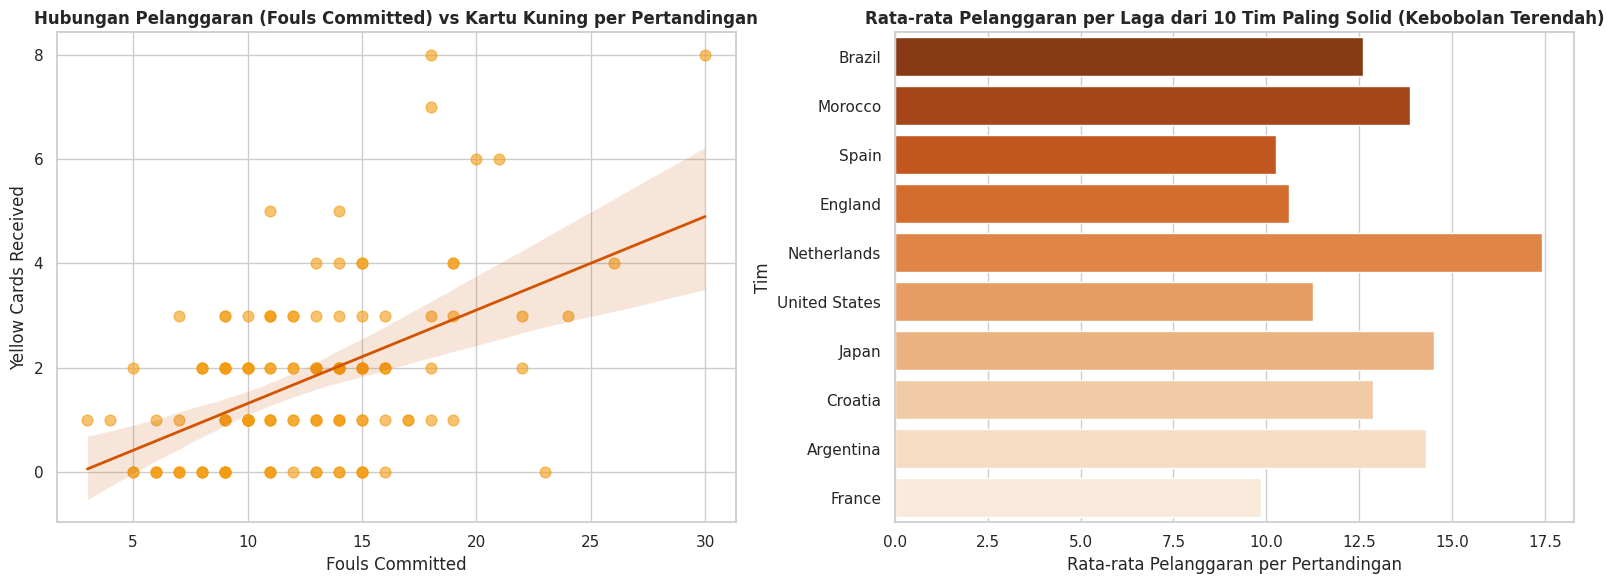

In [36]:
# 4. Visualisasi Analisis Pelanggaran dan Kartu vs Soliditas Pertahanan
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot A: Hubungan jumlah pelanggaran dengan jumlah kartu kuning yang diterima per laga
sns.regplot(
    ax=axes[0],
    data=team_defense_behavior,
    x='fouls_committed',
    y='yellow_cards',
    scatter_kws={'alpha': 0.6, 'color': '#f39c12', 's': 60},
    line_kws={'color': '#d35400', 'linewidth': 2}
)
axes[0].set_title('Hubungan Pelanggaran (Fouls Committed) vs Kartu Kuning per Pertandingan', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Fouls Committed')
axes[0].set_ylabel('Yellow Cards Received')

# Plot B: Rata-rata Pelanggaran oleh 10 Tim dengan Kebobolan Terendah (Pertahanan Solid)
top_solid_10 = solid_defense_teams.head(10)
sns.barplot(
    ax=axes[1],
    data=top_solid_10,
    x='avg_fouls_committed',
    y='team',
    palette='Oranges_r',
    hue='team',
    legend=False
)
axes[1].set_title('Rata-rata Pelanggaran per Laga dari 10 Tim Paling Solid (Kebobolan Terendah)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Rata-rata Pelanggaran per Pertandingan')
axes[1].set_ylabel('Tim')

plt.tight_layout()
plt.show()
